# Metoda składowych głównych

**Autor:** Jakub Psarski <br />
**Data:** 04.11.2026

Program wyszukuje w bazie emotikonę najbardziej podobną do zapytania. Obrazy są opisywane wektorami cech FFT oraz Haar, których wymiarowość redukowana jest metodą PCA. Porównywane są trzy podejścia: PCA na cechach FFT, PCA na cechach Haar oraz PCA na konkatenacji znormalizowanych cech FFT i Haar. Klasyfikacja odbywa się za pomocą k-NN.

## Importy i parametry

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier

np.random.seed(0)
WAVELET = "haar"
LEVELS = 4
N_QUERIES = 200
N_COMPONENTS = 10
K = 5

## Baza emotikon i zapytania

In [2]:
def make_emoji(c):
    img = np.zeros((64, 64), np.uint8)
    cv2.circle(img, (32, 32), 24, 255, -1)
    cv2.circle(img, (24, 24), 4, 0, -1)
    cv2.circle(img, (40, 24), 4, 0, -1)
    if c == 0:
        cv2.ellipse(img, (32, 36), (13, 10), 0, 0, 180, 0, -1)
    elif c == 1:
        cv2.ellipse(img, (32, 48), (12, 7), 0, 180, 360, 0, 4)
    elif c == 2:
        cv2.rectangle(img, (21, 40), (43, 44), 0, -1)
    else:
        cv2.circle(img, (32, 42), 7, 0, -1)
    return img


def transform(img):
    M = cv2.getRotationMatrix2D(
        (32, 32), np.random.uniform(-30, 30),
        np.random.uniform(0.7, 1.1)
    )
    M[0, 1] += np.random.uniform(-0.2, 0.2)
    M[:, 2] += np.random.uniform(-5, 5, 2)
    return cv2.warpAffine(img, M, (64, 64), flags=cv2.INTER_NEAREST)


names = np.array(["happy", "sad", "neutral", "surprised"])
db_labels = np.repeat(np.arange(4), 100)
db_imgs = np.array([transform(make_emoji(c)) for c in db_labels])
q_labels = np.random.randint(4, size=N_QUERIES)
q_imgs = np.array([transform(make_emoji(c)) for c in q_labels])
print("database size:", len(db_imgs))
print("queries:", len(q_imgs))

database size: 400
queries: 200


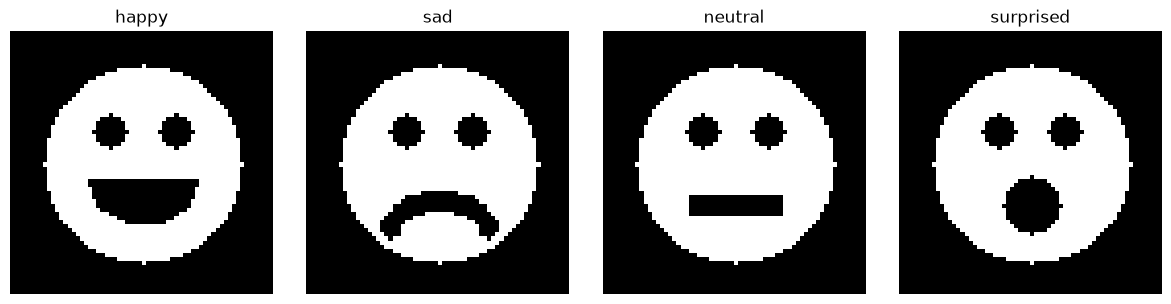

In [3]:
plt.figure(figsize=(12, 3))
for c in range(4):
    plt.subplot(1, 4, c + 1)
    plt.imshow(make_emoji(c), cmap="gray")
    plt.title(names[c])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Cechy FFT i Haar

In [4]:
def fft_features(img):
    F = np.abs(np.fft.fftshift(np.fft.fft2(img / 255.0)))
    return np.log1p(F[28:36, 28:36]).ravel()


def haar_features(img):
    coeffs = pywt.wavedec2(img / 255.0, wavelet=WAVELET, level=LEVELS)
    bands = [coeffs[0]] + [b for details in coeffs[1:] for b in details]
    return np.array([[np.abs(b).mean(), b.std()] for b in bands]).ravel()


D_fft = np.array([fft_features(im) for im in db_imgs])
Q_fft = np.array([fft_features(im) for im in q_imgs])
D_haar = np.array([haar_features(im) for im in db_imgs])
Q_haar = np.array([haar_features(im) for im in q_imgs])
print("FFT features:", D_fft.shape)
print("Haar features:", D_haar.shape)

FFT features: (400, 64)
Haar features: (400, 26)


## PCA i k-NN

In [5]:
def pca(D, Q, n):
    p = PCA(n_components=n).fit(D)
    return p.transform(D), p.transform(Q)


def normalize(D, Q):
    mean, std = D.mean(axis=0), D.std(axis=0) + 1e-9
    return (D - mean) / std, (Q - mean) / std


def knn_accuracy(D, Q, k):
    knn = KNeighborsClassifier(n_neighbors=k).fit(D, db_labels)
    return np.mean(knn.predict(Q) == q_labels) * 100


Dn_fft, Qn_fft = normalize(D_fft, Q_fft)
Dn_haar, Qn_haar = normalize(D_haar, Q_haar)
D_cat = np.hstack([Dn_fft, Dn_haar])
Q_cat = np.hstack([Qn_fft, Qn_haar])

D_fft_pca, Q_fft_pca = pca(D_fft, Q_fft, N_COMPONENTS)
D_haar_pca, Q_haar_pca = pca(D_haar, Q_haar, N_COMPONENTS)
D_cat_pca, Q_cat_pca = pca(D_cat, Q_cat, N_COMPONENTS)

print("FFT:", D_fft.shape, "->", D_fft_pca.shape)
print("Haar:", D_haar.shape, "->", D_haar_pca.shape)
print("concatenation:", D_cat.shape, "->", D_cat_pca.shape)

FFT: (400, 64) -> (400, 10)
Haar: (400, 26) -> (400, 10)
concatenation: (400, 90) -> (400, 10)


## Porównanie metod

FFT                    accuracy: 69.5%
FFT + PCA              accuracy: 60.0%
Haar                   accuracy: 50.0%
Haar + PCA             accuracy: 49.5%
concatenation          accuracy: 81.5%
concatenation + PCA    accuracy: 73.0%


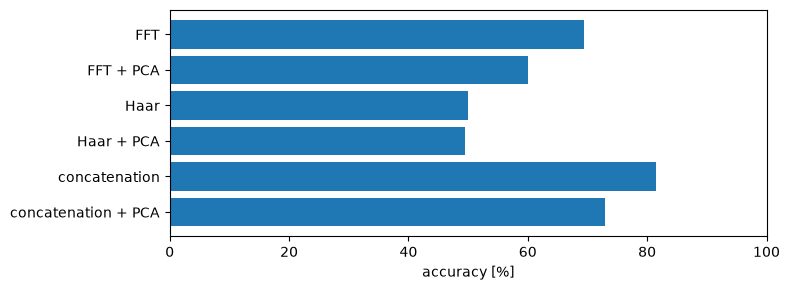

In [6]:
results = {
    "FFT": knn_accuracy(D_fft, Q_fft, K),
    "FFT + PCA": knn_accuracy(D_fft_pca, Q_fft_pca, K),
    "Haar": knn_accuracy(D_haar, Q_haar, K),
    "Haar + PCA": knn_accuracy(D_haar_pca, Q_haar_pca, K),
    "concatenation": knn_accuracy(D_cat, Q_cat, K),
    "concatenation + PCA": knn_accuracy(D_cat_pca, Q_cat_pca, K),
}

for name, acc in results.items():
    print(f"{name:22s} accuracy: {acc:.1f}%")

plt.figure(figsize=(8, 3))
plt.barh(list(results.keys()), list(results.values()))
plt.xlabel("accuracy [%]")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Wpływ liczby składowych głównych

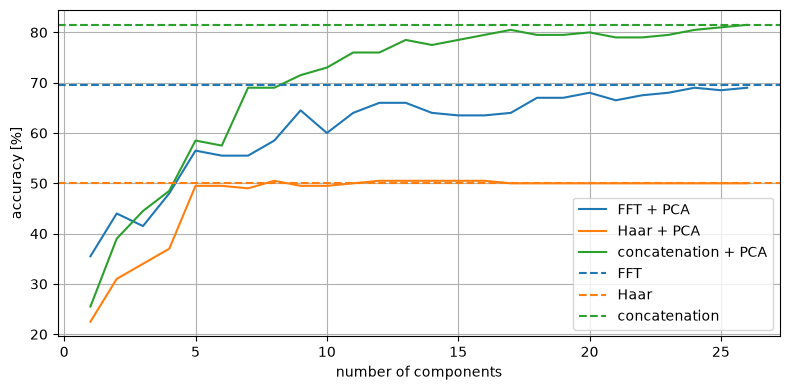

In [7]:
ns = range(1, 27)
acc_fft = [knn_accuracy(*pca(D_fft, Q_fft, n), K) for n in ns]
acc_haar = [knn_accuracy(*pca(D_haar, Q_haar, n), K) for n in ns]
acc_cat = [knn_accuracy(*pca(D_cat, Q_cat, n), K) for n in ns]

plt.figure(figsize=(8, 4))
l1, = plt.plot(ns, acc_fft, label="FFT + PCA")
l2, = plt.plot(ns, acc_haar, label="Haar + PCA")
l3, = plt.plot(ns, acc_cat, label="concatenation + PCA")
plt.axhline(
    knn_accuracy(D_fft, Q_fft, K),
    color=l1.get_color(),
    linestyle="--",
    label="FFT"
)
plt.axhline(
    knn_accuracy(D_haar, Q_haar, K),
    color=l2.get_color(),
    linestyle="--",
    label="Haar"
)
plt.axhline(
    knn_accuracy(D_cat, Q_cat, K),
    color=l3.get_color(),
    linestyle="--",
    label="concatenation"
)
plt.xlabel("number of components")
plt.ylabel("accuracy [%]")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## Wnioski

PCA zmniejsza wymiar wektorów cech kosztem niewielkiego spadku skuteczności: dla 10 składowych FFT spada z 69,5% do 60%, a Haar praktycznie się nie zmienia (50% -> 49,5%), bo wektor Haar i tak niesie mało informacji. Najlepsze wyniki daje konkatenacja znormalizowanych cech FFT i Haar – bez PCA 81,5%, po redukcji z 90 do 10 wymiarów 73%, czyli nadal więcej niż każda z cech osobno. Normalizacja przed konkatenacją jest konieczna, bo cechy FFT i Haar mają różne zakresy wartości i bez niej PCA wybrałoby głównie kierunki o dużych wartościach. Z wykresu widać, że po ok. 10–15 składowych dokładność przestaje istotnie rosnąć (dla Haar już po 5), więc dalsze zwiększanie wymiaru niewiele daje.